# 03 · Three-Phase Fine-Tuning
**Chest X-Ray Classification with ResNet50 Transfer Learning (TensorFlow / Keras)**  
*Task 2 · Sections 2.7-2.9* · MSc Data Science group project

**In this notebook**
- Cosine-annealing learning-rate schedule
- Phase 1: frozen backbone, head only (best val 96.31 %)
- Phase 2: top 55 ResNet50 layers unfrozen (best val 97.78 %)
- Phase 3: all 185 layers at LR 5e-6 (best val 98.42 %)

> **How to use these notebooks.** The outputs below come from one complete run on a Kaggle Tesla T4 GPU. Each part builds on objects created earlier (data generators, the trained model, predictions), so the part notebooks are for reading and review. To reproduce the results, run [`00_full_pipeline_run_all.ipynb`](00_full_pipeline_run_all.ipynb) top to bottom.

[← Transfer Learning Model & Preprocessing](02_transfer_learning_model.ipynb) · [Evaluation & Test-Time Augmentation →](04_evaluation_and_tta.ipynb)

---

### 2.7 Cosine Annealing Learning Rate Schedule

Instead of a fixed learning rate, we use cosine annealing which smoothly decays the LR from its initial value to near-zero over the course of training. This avoids abrupt LR drops and leads to more stable convergence.

In [ ]:
# ── Cosine-annealing LR schedule ────────────────────────────
def cosine_schedule(init_lr, total_epochs):
    """Smoothly decays LR from init_lr → ~0 following a cosine curve."""
    def fn(epoch, lr):
        return init_lr * (1 + math.cos(math.pi * epoch / total_epochs)) / 2
    return fn


### 2.8 Three-Phase Training Strategy

Training is split into 3 progressive phases to avoid catastrophic forgetting:

| Phase | Layers Trained | LR | Epochs | Purpose |
|---|---|---|---|---|
| Phase 1 | Head only (backbone frozen) | 1e-3 | 20 | Learn task-specific features without disturbing ImageNet weights |
| Phase 2 | Top 55 ResNet layers + head | 1e-4 | 35 | Adapt high-level features (conv4+conv5) to X-ray domain |
| Phase 3 | All 185 layers | 5e-6 | 20 | Fine global adjustment at very small LR |

**Callbacks used in every phase:**
- `EarlyStopping` — stops if val_loss doesn't improve
- `ReduceLROnPlateau` — halves LR on plateau
- `ModelCheckpoint` — saves best val_accuracy checkpoint
- `LearningRateScheduler` — cosine annealing within each phase

#### Phase 1 — Train Head Only (Backbone Frozen)

In [ ]:
# ══════════════════════════════════════════════════════════
# PHASE 1 — Frozen backbone, train classification head only
# ══════════════════════════════════════════════════════════
model.compile(
    optimizer=Adam(learning_rate=LR_P1),
    loss=loss_fn,
    metrics=['accuracy']
)

callbacks_p1 = [
    EarlyStopping(monitor='val_loss', patience=5,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=2, min_lr=1e-7, verbose=1),
    ModelCheckpoint('best_p1.keras', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
    LearningRateScheduler(cosine_schedule(LR_P1, EPOCHS_P1), verbose=0)
]

print("🚀 Phase 1 — Training head only (ResNet50 frozen)\n")
history_p1 = model.fit(
    train_generator, epochs=EPOCHS_P1,
    validation_data=val_generator,
    class_weight=class_weights,
    callbacks=callbacks_p1
)
print(f"\n✅ Phase 1 done  |  Best val acc: {max(history_p1.history['val_accuracy']):.4f}")


🚀 Phase 1 — Training head only (ResNet50 frozen)

Epoch 1/20


I0000 00:00:1773722581.625874     127 service.cc:152] XLA service 0x7c329000cb80 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1773722581.625923     127 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1773722581.625930     127 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1773722583.748055     127 cuda_dnn.cc:529] Loaded cuDNN version 91002


  1/169 ━━━━━━━━━━━━━━━━━━━━ 48:07 17s/step - accuracy: 0.1562 - loss: 1.7679

I0000 00:00:1773722590.306262     127 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 940ms/step - accuracy: 0.7930 - loss: 0.8051
Epoch 1: val_accuracy improved from -inf to 0.90823, saving model to best_p1.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 212s 1s/step - accuracy: 0.7934 - loss: 0.8044 - val_accuracy: 0.9082 - val_loss: 0.5281 - learning_rate: 0.0010
Epoch 2/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 733ms/step - accuracy: 0.8955 - loss: 0.5864
Epoch 2: val_accuracy improved from 0.90823 to 0.92616, saving model to best_p1.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 147s 868ms/step - accuracy: 0.8956 - loss: 0.5862 - val_accuracy: 0.9262 - val_loss: 0.4970 - learning_rate: 9.9384e-04
Epoch 3/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 734ms/step - accuracy: 0.9246 - loss: 0.5261
Epoch 3: val_accuracy improved from 0.92616 to 0.94198, saving model to best_p1.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 147s 868ms/step - accuracy: 0.9247 - loss: 0.5261 - val_accuracy: 0.9420 - val_loss: 0.4782 - learning_rate: 9.7553e-04
Epoch 4/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 735ms/ste

#### Phase 2 — Partial Fine-Tuning (Top 55 Layers Unfrozen)

We unfreeze from layer 120 instead of 145 (original), opening up both conv4 and conv5 blocks. Medical images have very different textures from ImageNet, so adapting mid-level features significantly helps.

In [ ]:
# ══════════════════════════════════════════════════════════
# PHASE 2 — Unfreeze top 55 ResNet50 layers (conv4 + conv5)
# ══════════════════════════════════════════════════════════
# ResNet50 has 175 layers total.
# Original: freeze until layer 145 → only top 30 layers unfrozen (conv5 only)
# Improved: freeze until layer 120 → top 55 layers unfrozen (conv4 + conv5)
# This allows the model to adapt higher-level and mid-level features,
# which is more beneficial for medical images vs ImageNet features.
FREEZE_UNTIL = 120   # was 145 — now unfreezes conv4 block as well

for layer in base_model.layers[:FREEZE_UNTIL]:
    layer.trainable = False
for layer in base_model.layers[FREEZE_UNTIL:]:
    layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=LR_P2),
    loss=loss_fn,
    metrics=['accuracy']
)

unfrozen = len([l for l in base_model.layers if l.trainable])
print(f"✅ Unfroze top {unfrozen} ResNet50 layers  (layers {FREEZE_UNTIL}–174)")
print(f"   Covers: conv4_block + entire conv5_block")
print(f"   Total trainable layers now: {len([l for l in model.layers if l.trainable])}")

callbacks_p2 = [
    EarlyStopping(monitor='val_loss', patience=7,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-8, verbose=1),
    ModelCheckpoint('best_p2.keras', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
    LearningRateScheduler(cosine_schedule(LR_P2, EPOCHS_P2), verbose=0)
]

print(f"\n🚀 Phase 2 — Partial fine-tuning (top 55 ResNet layers, {EPOCHS_P2} epochs)\n")
history_p2 = model.fit(
    train_generator, epochs=EPOCHS_P2,
    validation_data=val_generator,
    class_weight=class_weights,
    callbacks=callbacks_p2
)
print(f"\n✅ Phase 2 done  |  Best val acc: {max(history_p2.history['val_accuracy']):.4f}")

✅ Unfroze top 55 ResNet50 layers  (layers 120–174)
   Covers: conv4_block + entire conv5_block
   Total trainable layers now: 65

🚀 Phase 2 — Partial fine-tuning (top 55 ResNet layers, 35 epochs)

Epoch 1/35
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 811ms/step - accuracy: 0.9345 - loss: 0.4877
Epoch 1: val_accuracy improved from -inf to 0.95148, saving model to best_p2.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 196s 992ms/step - accuracy: 0.9346 - loss: 0.4875 - val_accuracy: 0.9515 - val_loss: 0.4642 - learning_rate: 1.0000e-04
Epoch 2/35
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 758ms/step - accuracy: 0.9543 - loss: 0.4410
Epoch 2: val_accuracy improved from 0.95148 to 0.96941, saving model to best_p2.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 151s 891ms/step - accuracy: 0.9543 - loss: 0.4410 - val_accuracy: 0.9694 - val_loss: 0.4174 - learning_rate: 9.9799e-05
Epoch 3/35
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 759ms/step - accuracy: 0.9697 - loss: 0.4140
Epoch 3: val_accuracy did not improve from 0.96941
169/169 ━━━━━━━━━━━━━

#### Phase 3 — Full Fine-Tuning (All Layers, Very Small LR)

In [ ]:
# ══════════════════════════════════════════════════════════
# PHASE 3 — Full fine-tuning (all layers, very small LR)
# ══════════════════════════════════════════════════════════
for layer in model.layers:
    layer.trainable = True

model.compile(
    optimizer=Adam(learning_rate=LR_P3),
    loss=loss_fn,
    metrics=['accuracy']
)

print(f"✅ All layers unfrozen")
print(f"   Trainable layers: {len([l for l in model.layers if l.trainable])}")

callbacks_p3 = [
    EarlyStopping(monitor='val_loss', patience=7,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=3, min_lr=1e-9, verbose=1),
    ModelCheckpoint('best_final.keras', monitor='val_accuracy',
                    save_best_only=True, verbose=1),
    LearningRateScheduler(cosine_schedule(LR_P3, EPOCHS_P3), verbose=0)
]

print("\n🚀 Phase 3 — Full fine-tuning (all ResNet50 layers)\n")
history_p3 = model.fit(
    train_generator, epochs=EPOCHS_P3,
    validation_data=val_generator,
    class_weight=class_weights,
    callbacks=callbacks_p3
)
print(f"\n✅ Phase 3 done  |  Best val acc: {max(history_p3.history['val_accuracy']):.4f}")


✅ All layers unfrozen
   Trainable layers: 185

🚀 Phase 3 — Full fine-tuning (all ResNet50 layers)

Epoch 1/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 940ms/step - accuracy: 0.9659 - loss: 0.4164
Epoch 1: val_accuracy improved from -inf to 0.98418, saving model to best_final.keras
169/169 ━━━━━━━━━━━━━━━━━━━━ 246s 1s/step - accuracy: 0.9659 - loss: 0.4164 - val_accuracy: 0.9842 - val_loss: 0.4007 - learning_rate: 5.0000e-06
Epoch 2/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 813ms/step - accuracy: 0.9746 - loss: 0.3960
Epoch 2: val_accuracy did not improve from 0.98418
169/169 ━━━━━━━━━━━━━━━━━━━━ 159s 938ms/step - accuracy: 0.9746 - loss: 0.3960 - val_accuracy: 0.9747 - val_loss: 0.4092 - learning_rate: 4.9692e-06
Epoch 3/20
169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 816ms/step - accuracy: 0.9780 - loss: 0.3918
Epoch 3: val_accuracy did not improve from 0.98418
169/169 ━━━━━━━━━━━━━━━━━━━━ 159s 941ms/step - accuracy: 0.9780 - loss: 0.3918 - val_accuracy: 0.9810 - val_loss: 0.3964 - learning_rate: 4.8776e-06
Epoc

### 2.9 Training History Visualisation

The combined accuracy and loss curves across all 3 phases are plotted below. Phase boundaries are marked with dashed vertical lines. The 95% accuracy target line is shown in green.

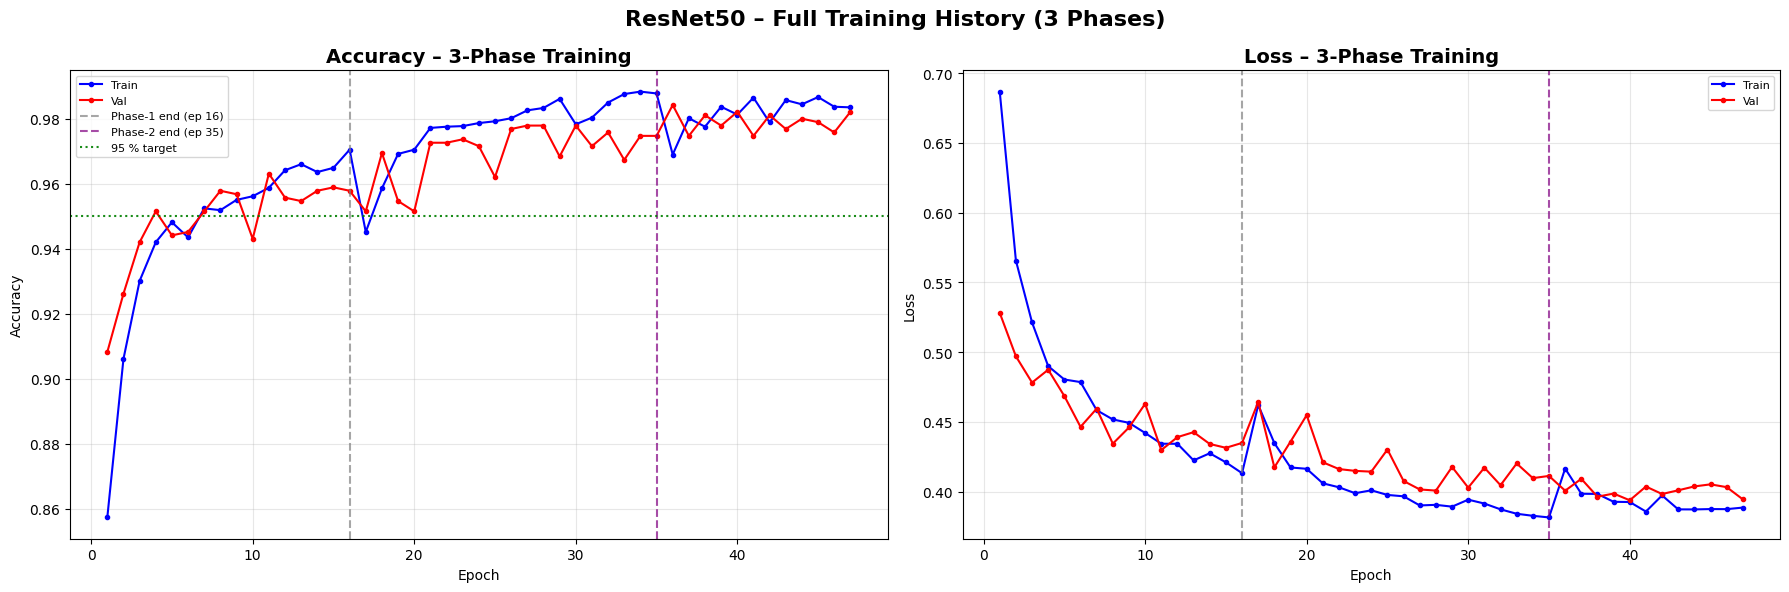

✅ Training history saved


In [ ]:
# ── Combined 3-phase training history plot ──────────────────
all_acc      = (history_p1.history['accuracy']     +
                history_p2.history['accuracy']     +
                history_p3.history['accuracy'])
all_val_acc  = (history_p1.history['val_accuracy'] +
                history_p2.history['val_accuracy'] +
                history_p3.history['val_accuracy'])
all_loss     = (history_p1.history['loss']         +
                history_p2.history['loss']         +
                history_p3.history['loss'])
all_val_loss = (history_p1.history['val_loss']     +
                history_p2.history['val_loss']     +
                history_p3.history['val_loss'])

p1_end = len(history_p1.history['accuracy'])
p2_end = p1_end + len(history_p2.history['accuracy'])
ep     = range(1, len(all_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

axes[0].plot(ep, all_acc,     'b-o', label='Train', markersize=3)
axes[0].plot(ep, all_val_acc, 'r-o', label='Val',   markersize=3)
axes[0].axvline(p1_end, color='gray',   ls='--', alpha=.7,
                label=f'Phase-1 end (ep {p1_end})')
axes[0].axvline(p2_end, color='purple', ls='--', alpha=.7,
                label=f'Phase-2 end (ep {p2_end})')
axes[0].axhline(0.95,   color='green',  ls=':',  alpha=.9,
                label='95 % target')
axes[0].set_title('Accuracy – 3-Phase Training', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=8);  axes[0].grid(True, alpha=.3)

axes[1].plot(ep, all_loss,     'b-o', label='Train', markersize=3)
axes[1].plot(ep, all_val_loss, 'r-o', label='Val',   markersize=3)
axes[1].axvline(p1_end, color='gray',   ls='--', alpha=.7)
axes[1].axvline(p2_end, color='purple', ls='--', alpha=.7)
axes[1].set_title('Loss – 3-Phase Training', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8);  axes[1].grid(True, alpha=.3)

plt.suptitle('ResNet50 – Full Training History (3 Phases)',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('full_training_history.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Training history saved")


> **Interpretation.** Phase 1 (frozen backbone) reached 96.31 % validation accuracy before early stopping at epoch 16. Unfreezing the top 55 layers in Phase 2 lifted it to 97.78 %, and full fine-tuning at a very small learning rate in Phase 3 reached the best value of **98.42 %** in its first epoch. Each phase starts from the previous best weights, so accuracy improves step by step without the drop that full fine-tuning from the start would cause.

---

[← Transfer Learning Model & Preprocessing](02_transfer_learning_model.ipynb) · [Next: Evaluation & Test-Time Augmentation →](04_evaluation_and_tta.ipynb)